# imports

In [1]:
# %%capture cap --no-stderr

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from typing import List
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import nltk
import pickle
import pymorphy3
import re
from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

import datasets
import gc
import peft
import torch
import trl
from torch.nn.utils.rnn import pad_sequence
from transformers import T5ForConditionalGeneration, AutoTokenizer
from transformers import AutoModelForSeq2SeqLM

# nltk.download('punkt')
# nltk.download('stopwords')
# nltk.download('punkt_tab')

C:\Users\Дмитрий\AppData\Roaming\Python\Python312\site-packages\trl\trainer\ppo_config.py:141: UserWarning: The `optimize_cuda_cache` arguement will be deprecated soon, please use `optimize_device_cache` instead.
  warnings.warn(


# Data transformers

In [2]:
df = pd.read_csv('comments.csv')
df.head()

,comment,toxic
0,"Верблюдов-то за что? Дебилы, бл...\n",1.0
1,"Хохлы, это отдушина затюканого россиянина, мол...",1.0
2,Собаке - собачья смерть\n,1.0
3,"Страницу обнови, дебил. Это тоже не оскорблени...",1.0
4,"тебя не убедил 6-страничный пдф в том, что Скр...",1.0


In [3]:
class LemmatizeTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        self.morph = pymorphy3.MorphAnalyzer()
        self.stopwords = stopwords.words("russian") + ['это', 'её', '']
        return self

    def transform(self, X):
        def clean_text(text):
            text = text.lower()
            text = re.sub(r'http\S+', '', text)
            text = re.sub(r'www\S+', '', text)
            text = re.sub(r"\'s", " ", text)
            text = re.sub('\W', ' ', text)
            text = re.sub('\s+', ' ', text)
            text = text.strip(' ')
            return text


        X_copy = X.copy()

        if isinstance(X_copy, list):
            X_copy = map(clean_text, X_copy)
            X_copy = map(lambda x: list(map(lambda word: self.morph.parse(word)[0].normal_form, word_tokenize(x))), X_copy)
            X_copy = map(lambda x: [word for word in x if word not in self.stopwords], X_copy)
            X_copy = map(lambda x: ' '.join(x), X_copy)
            X_copy = list(X_copy)
        else:
            X_copy['comment'] = X_copy['comment'].apply(clean_text)
            X_copy['comment'] = X_copy['comment'].apply(lambda x: list(map(lambda word: self.morph.parse(word)[0].normal_form, word_tokenize(x))))
            X_copy['comment'] = X_copy['comment'].apply(lambda x: [word for word in x if word not in self.stopwords])
            X_copy['comment'] = X_copy['comment'].apply(lambda x: ' '.join(x))

        return X_copy

<>:16: SyntaxWarning: invalid escape sequence '\W'
<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\W'
<>:17: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Дмитрий\AppData\Local\Temp\ipykernel_11056\1817971779.py:16: SyntaxWarning: invalid escape sequence '\W'
  text = re.sub('\W', ' ', text)
C:\Users\Дмитрий\AppData\Local\Temp\ipykernel_11056\1817971779.py:17: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub('\s+', ' ', text)


In [4]:
# lemmatizer = LemmatizeTransformer()
# lemmatizer.fit(df)
# df = lemmatizer.transform(df)
# df

In [5]:
# df = df[df['comment'] != '']

In [6]:
# df.isna().value_counts()

In [7]:
# df.to_csv('comments_lemmatized.csv')

# BoW + LogisticRegression [roc-auc 0.9162]

In [8]:
df = pd.read_csv('comments_lemmatized.csv', index_col=0)

In [9]:
RANDOM_STATE=42


X = df.drop(columns=['toxic'])
y = df['toxic']
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=RANDOM_STATE, test_size=0.25)

In [10]:
class CountTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        assert X.shape[1] == 1
        self.vectorizer_ = CountVectorizer()
        self.vectorizer_.fit(X[X.columns[0]].astype('str'))
        return self

    def transform(self, X):
        assert X.shape[1] == 1
        return self.vectorizer_.transform(X[X.columns[0]].astype('str'))


def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

In [11]:
count_transformer = Pipeline(steps=[
    ('count_transformer', CountTransformer())
])

comment_transformer = ColumnTransformer(transformers=[
    ('comments', count_transformer, ['comment'])
])

preprocessor = Pipeline(steps=[('comment_transformer', comment_transformer)])

lr_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', LogisticRegression())])


lr_pipeline.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('comment_transformer',
                                  ColumnTransformer(transformers=[('comments',
                                                                   Pipeline(steps=[('count_transformer',
                                                                                    CountTransformer())]),
                                                                   ['comment'])]))])),
                ('model', LogisticRegression())])

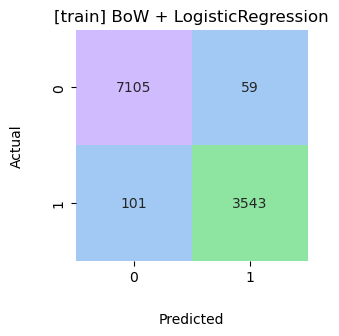

accuracy:	0.9851961509992598
precision:	0.9851869656703359
recall:		0.9851961509992598
f1:		0.9851748812311878


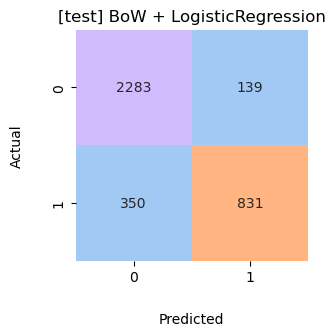

accuracy:	0.8642797668609492
precision:	0.8636724317747787
recall:		0.8642797668609492
f1:		0.8604556416968637


In [12]:
y_pred = lr_pipeline.predict(Xtrain)
get_metrics(ytrain, y_pred, '[train] BoW + LogisticRegression')
y_pred = lr_pipeline.predict(Xtest)
get_metrics(ytest, y_pred, '[test] BoW + LogisticRegression')

In [13]:
y_prob = lr_pipeline.predict_proba(Xtrain)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = lr_pipeline.predict_proba(Xtest)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9983837577324358
roc_auc/test:	0.916262932713183


# Boosting [roc-auc 0.8756], Bagging [roc-auc 0.8913]

##  RandomForest

In [10]:
from sklearn.ensemble import RandomForestClassifier


count_transformer = Pipeline(steps=[
    ('count_transformer', CountTransformer())
])

comment_transformer = ColumnTransformer(transformers=[
    ('comments', count_transformer, ['comment'])
])

preprocessor = Pipeline(steps=[('comment_transformer', comment_transformer)])

rf_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', RandomForestClassifier(random_state=RANDOM_STATE))])


rf_pipeline.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('comment_transformer',
                                  ColumnTransformer(transformers=[('comments',
                                                                   Pipeline(steps=[('count_transformer',
                                                                                    CountTransformer())]),
                                                                   ['comment'])]))])),
                ('model', RandomForestClassifier(random_state=42))])

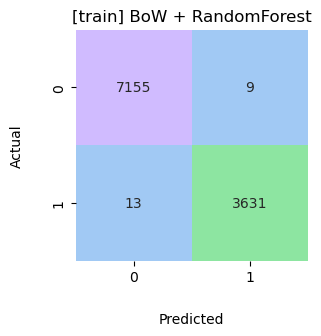

accuracy:	0.9979644707623982
precision:	0.9979642269017761
recall:		0.9979644707623982
f1:		0.9979641959119185


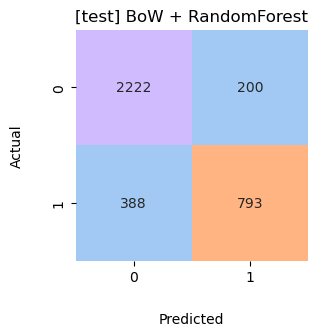

accuracy:	0.8368026644462948
precision:	0.834050190766748
recall:		0.8368026644462948
f1:		0.8327948927873798


In [11]:
y_pred = rf_pipeline.predict(Xtrain)
get_metrics(ytrain, y_pred, '[train] BoW + RandomForest')
y_pred = rf_pipeline.predict(Xtest)
get_metrics(ytest, y_pred, '[test] BoW + RandomForest')

In [12]:
y_prob = rf_pipeline.predict_proba(Xtrain)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = rf_pipeline.predict_proba(Xtest)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9999894275622533
roc_auc/test:	0.8989647186984117


### hyperparameters

In [ ]:
ct = CountTransformer()
ct.fit(Xtrain)
Xtrain_ = ct.transform(Xtrain)
Xtest_ = ct.transform(Xtest)

In [ ]:
import numpy as np
from sklearn.model_selection import GridSearchCV


params = {
    'n_estimators': np.arange(10, 200, 20),
    'max_depth': list(np.arange(2, 21, 3)) + [None],
}

clf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), params, cv=3, verbose=2, scoring='roc_auc')
clf.fit(Xtrain_, ytrain)

Fitting 3 folds for each of 80 candidates, totalling 240 fits
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.2s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.2s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=70; total time=   0.5s
[CV] END .......................max_depth=2, n_estimators=70; total time=   0.5s
[CV] END .......................max_depth=2, n_

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [2, 5, 8, 11, 14, 17, 20, None],
                         'n_estimators': array([ 10,  30,  50,  70,  90, 110, 130, 150, 170, 190])},
             scoring='roc_auc', verbose=2)

In [ ]:
best_params = clf.best_params_
clf.best_score_, clf.best_estimator_, best_params

(0.897113731110572,
 RandomForestClassifier(max_depth=20, n_estimators=190, random_state=42),
 {'max_depth': 20, 'n_estimators': 190})

In [ ]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, **best_params)
rf.fit(Xtrain_, ytrain)

RandomForestClassifier(max_depth=20, n_estimators=190, random_state=42)

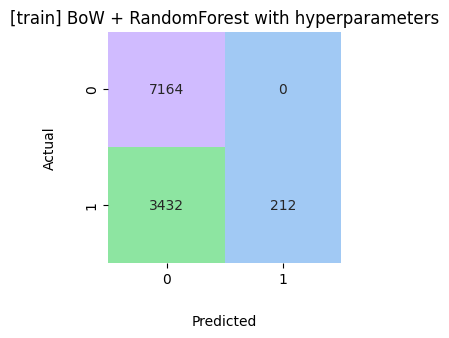

accuracy:	0.6824574389341229
precision:	0.7853081438773176
recall:		0.6824574389341229
f1:		0.5718258884239362


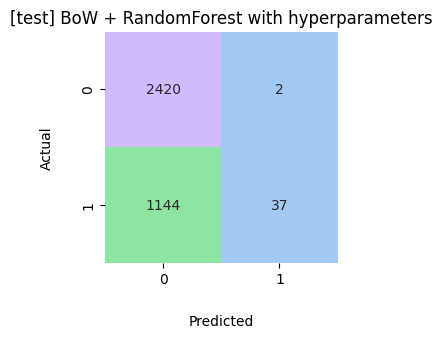

accuracy:	0.6819317235636969
precision:	0.767417096494717
recall:		0.6819317235636969
f1:		0.5634056333781431


In [ ]:
y_pred = rf.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + RandomForest with hyperparameters')
y_pred = rf.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + RandomForest with hyperparameters')

In [ ]:
y_prob = rf.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = rf.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9531746732197394
roc_auc/test:	0.8913921287436433


## GradientBoosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier


gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(Xtrain_, ytrain)

GradientBoostingClassifier(random_state=42)

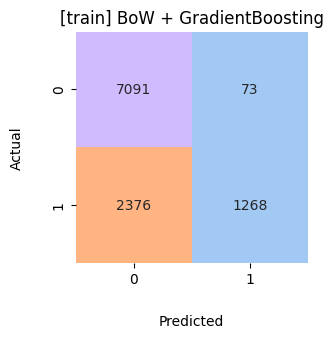

accuracy:	0.7734085862324205
precision:	0.8152879190835995
recall:		0.7734085862324205
f1:		0.7367563353199219


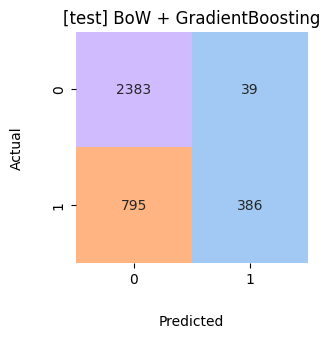

accuracy:	0.768526228143214
precision:	0.8017609839256783
recall:		0.768526228143214
f1:		0.7296693342928215


In [ ]:
y_pred = gb.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + GradientBoosting')
y_pred = gb.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + GradientBoosting')

In [ ]:
y_prob = gb.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = gb.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.8533927718847929
roc_auc/test:	0.8182882566034886


In [ ]:
import numpy as np
from sklearn.model_selection import GridSearchCV


params = {
    'n_estimators': np.arange(10, 200, 20),
    'max_depth': [2, 4, 6],
}

clf = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE), params, cv=3, verbose=2, scoring='roc_auc')
clf.fit(Xtrain_, ytrain)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV] END .......................max_depth=2, n_estimators=10; total time=   2.0s
[CV] END .......................max_depth=2, n_estimators=10; total time=   2.5s
[CV] END .......................max_depth=2, n_estimators=10; total time=   2.6s
[CV] END .......................max_depth=2, n_estimators=30; total time=   5.8s
[CV] END .......................max_depth=2, n_estimators=30; total time=   7.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   5.9s
[CV] END .......................max_depth=2, n_estimators=50; total time=  10.9s
[CV] END .......................max_depth=2, n_estimators=50; total time=  11.0s
[CV] END .......................max_depth=2, n_estimators=50; total time=  11.1s
[CV] END .......................max_depth=2, n_estimators=70; total time=  14.7s
[CV] END .......................max_depth=2, n_estimators=70; total time=  14.9s
[CV] END .......................max_depth=2, n_e

GridSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=42),
             param_grid={'max_depth': [2, 4, 6],
                         'n_estimators': array([ 10,  30,  50,  70,  90, 110, 130, 150, 170, 190])},
             scoring='roc_auc', verbose=2)

In [ ]:
best_params = clf.best_params_
clf.best_score_, clf.best_estimator_, best_params

(0.8724706451469193,
 GradientBoostingClassifier(max_depth=6, n_estimators=190, random_state=42),
 {'max_depth': 6, 'n_estimators': 190})

In [ ]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE, **best_params)
gb.fit(Xtrain_, ytrain)

GradientBoostingClassifier(max_depth=6, n_estimators=190, random_state=42)

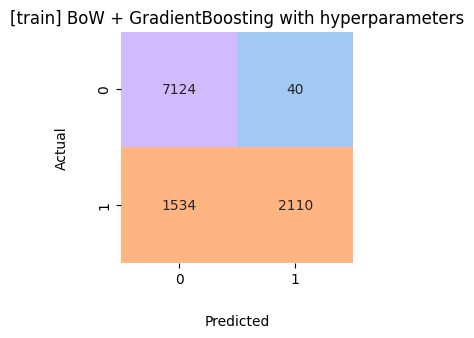

accuracy:	0.8543671354552184
precision:	0.8762867647914038
recall:		0.8543671354552184
f1:		0.8424669303128924


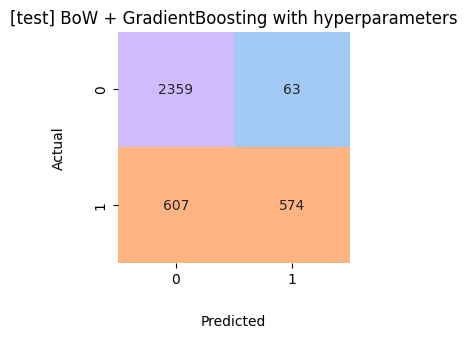

accuracy:	0.8140438523452679
precision:	0.8300107931820773
recall:		0.8140438523452679
f1:		0.7956095717066884


In [ ]:
y_pred = gb.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + GradientBoosting with hyperparameters')
y_pred = gb.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + GradientBoosting with hyperparameters')

In [ ]:
y_prob = clf.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = clf.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9524247004935643
roc_auc/test:	0.8756281503659302


# BERT [roc-auc 0.93402]

In [ ]:
df_train = pd.concat([Xtrain, ytrain.astype(int)], axis=1)
df_train

,comment,toxic
5049,козырёк второй фотка дешёвый сайдинг обшить вп...,1
4192,переключение поле ввод кнопка прочий интеракти...,0
10606,вокзал таксист очень сильно ценник упасть дешё...,0
9186,сколько угодный гундеть 43 маленький 50 любой ...,0
9971,запредельный цена питер москва лоукостер долет...,0
...,...,...
5191,знать откуда машина столько человек район новы...,0
13419,всё кроме тигр похожий обычный дворовый кот,0
5390,второй сезон полный хует,0
860,мда хотеть просто спасибо сказать обижёнка зад...,1


In [ ]:
from torch.utils.data import Dataset


class TextClassificationDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        encoding = self.tokenizer(text, return_tensors='pt', max_length=self.max_length, padding='max_length', truncation=True)
        return {'input_ids': encoding['input_ids'].flatten(), 'attention_mask': encoding['attention_mask'].flatten(), 'label': torch.tensor(label)}

In [ ]:
import torch
from torch import nn
from transformers import BertModel

class BERTClassifier(nn.Module):
    def __init__(self, bert_model_name, num_classes):
        super(BERTClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(bert_model_name)
        self.dropout = nn.Dropout(0.1)
        self.fc = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.pooler_output
        x = self.dropout(pooled_output)
        logits = self.fc(x)
        return logits

In [ ]:
import os
from torch.utils.data import DataLoader
from transformers import BertTokenizer, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm


def train(model, data_loader, optimizer, scheduler, device):
    model.train()
    for batch in tqdm(data_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = nn.CrossEntropyLoss()(outputs, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()


def evaluate(model, data_loader, device):
    model.eval()
    predictions = []
    actual_labels = []
    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            _, preds = torch.max(outputs, dim=1)
            predictions.extend(preds.cpu().tolist())
            actual_labels.extend(labels.cpu().tolist())
    return accuracy_score(actual_labels, predictions), classification_report(actual_labels, predictions)

In [ ]:
features = ['comment', 'toxic']
texts = df_train['comment'].tolist()
labels = df_train['toxic'].tolist()


bert_model_name = 'cointegrated/rubert-tiny'
num_classes = 2
max_length = 128
batch_size = 16
num_epochs = 4
learning_rate = 2e-5

train_texts, val_texts, train_labels, val_labels = train_test_split(texts, labels, test_size=0.2, random_state=RANDOM_STATE)

tokenizer = BertTokenizer.from_pretrained(bert_model_name)
train_dataset = TextClassificationDataset(train_texts, train_labels, tokenizer, max_length)
val_dataset = TextClassificationDataset(val_texts, val_labels, tokenizer, max_length)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = BERTClassifier(bert_model_name, num_classes).to(device)

optimizer = AdamW(model.parameters(), lr=learning_rate)
total_steps = len(train_dataloader) * num_epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")
    train(model, train_dataloader, optimizer, scheduler, device)
    accuracy, report = evaluate(model, val_dataloader, device)
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(report)

Epoch 1/4


100%|██████████| 541/541 [09:05<00:00,  1.01s/it]


Validation Accuracy: 0.8432
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1436
           1       0.74      0.82      0.78       726

    accuracy                           0.84      2162
   macro avg       0.82      0.84      0.83      2162
weighted avg       0.85      0.84      0.84      2162

Epoch 2/4


100%|██████████| 541/541 [09:03<00:00,  1.01s/it]


Validation Accuracy: 0.8626
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1436
           1       0.78      0.82      0.80       726

    accuracy                           0.86      2162
   macro avg       0.84      0.85      0.85      2162
weighted avg       0.86      0.86      0.86      2162

Epoch 3/4


100%|██████████| 541/541 [09:00<00:00,  1.00it/s]


Validation Accuracy: 0.8636
              precision    recall  f1-score   support

           0       0.90      0.89      0.90      1436
           1       0.79      0.80      0.80       726

    accuracy                           0.86      2162
   macro avg       0.85      0.85      0.85      2162
weighted avg       0.86      0.86      0.86      2162

Epoch 4/4


100%|██████████| 541/541 [09:03<00:00,  1.00s/it]


Validation Accuracy: 0.8677
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1436
           1       0.81      0.80      0.80       726

    accuracy                           0.87      2162
   macro avg       0.85      0.85      0.85      2162
weighted avg       0.87      0.87      0.87      2162



In [ ]:
torch.save(model.state_dict(), f'rubert-tiny-e4.pth')

In [ ]:
def predict(text, model, tokenizer, device, max_length=128):
    model.eval()
    encoding = tokenizer(text, return_tensors='pt', max_length=max_length, padding='max_length', truncation=True)
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs, dim=1)
    return 1 if preds.item() == 1 else 0


ypred = []
for comment in tqdm(Xtest['comment']):
    ypred.append(predict(comment, model, tokenizer, device))

100%|██████████| 3603/3603 [01:18<00:00, 45.62it/s]


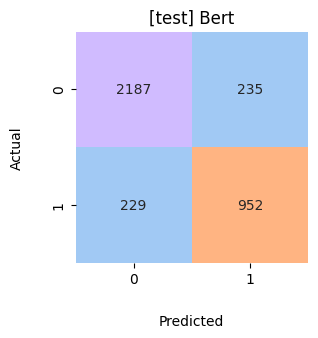

accuracy:	0.8712184290868721
precision:	0.871390274761857
recall:		0.8712184290868721
f1:		0.8713017251286655


In [ ]:
get_metrics(ytest, ypred, '[test] Bert')

In [ ]:
def predict_proba(text, model, tokenizer, device, max_length=128):
    model.eval()
    encoding = tokenizer(text, return_tensors='pt', max_length=max_length, padding='max_length', truncation=True)
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.softmax(outputs, dim=1)
    return preds[:, 1].item()


y_prob = []
for comment in tqdm(Xtest['comment']):
    y_prob.append(predict_proba(comment, model, tokenizer, device))
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

100%|██████████| 3603/3603 [01:18<00:00, 45.79it/s]

roc_auc/test:	0.934020001524272


# RL

## load seq2seq model

In [14]:
base_model_name = 'ai-forever/ruT5-base'
model_name = 's-nlp/ruT5-base-detox'

In [15]:
cache_dir = "D:/jupyter/" # fixes OSError: Unable to load vocabulary from file
cache_dir_tokenizers = cache_dir + "tokenizers/"
tokenizer = AutoTokenizer.from_pretrained(base_model_name, force_download=True, cache_dir=cache_dir_tokenizers)
model = T5ForConditionalGeneration.from_pretrained(model_name)

C:\Users\Дмитрий\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/1.00M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
input_ids = tokenizer.encode('Это полная хуйня!', return_tensors='pt').to(device)
output_ids = model.generate(input_ids, max_length=50, num_return_sequences=1)
output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(output_text)

Это полная ерунда!


## prepare dataset

In [17]:
class CleanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        def clean_text(text):
            text = text.lower()
            text = re.sub(r'http\S+', '', text)
            text = re.sub(r'www\S+', '', text)
            text = re.sub(r"\'s", " ", text)
            text = re.sub('\W', ' ', text)
            text = re.sub('\s+', ' ', text)
            text = text.strip(' ')
            return text


        X_copy = X.copy()
        X_copy['comment'] = X_copy['comment'].apply(clean_text)
        return X_copy

<>:14: SyntaxWarning: invalid escape sequence '\W'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\W'
<>:15: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Дмитрий\AppData\Local\Temp\ipykernel_11056\2016100263.py:14: SyntaxWarning: invalid escape sequence '\W'
  text = re.sub('\W', ' ', text)
C:\Users\Дмитрий\AppData\Local\Temp\ipykernel_11056\2016100263.py:15: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub('\s+', ' ', text)


In [18]:
df = pd.read_csv('comments.csv')
cleaner = CleanTransformer()
cleaner.fit(df)
df = cleaner.transform(df)
df = df[df['comment'] != '']
df = df[df['comment'].map(len) < 1000]
df

,comment,toxic
0,верблюдов то за что дебилы бл,1.0
1,хохлы это отдушина затюканого россиянина мол в...,1.0
2,собаке собачья смерть,1.0
3,страницу обнови дебил это тоже не оскорбление ...,1.0
4,тебя не убедил 6 страничный пдф в том что скри...,1.0
...,...,...
14407,вонючий совковый скот прибежал и ноет а вот и ...,1.0
14408,а кого любить гоблина тупорылого что ли или ка...,1.0
14409,посмотрел утомленных солнцем 2 и оказалось что...,0.0
14410,крымотред нарушает правила раздела т к в нем н...,1.0


In [19]:
RANDOM_STATE=42


X = df.drop(columns=['toxic'])
y = df['toxic']
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=RANDOM_STATE, test_size=0.25)
Xtrain.shape, Xtest.shape, ytrain.shape, ytest.shape

((10659, 1), (3554, 1), (10659,), (3554,))

In [20]:
ytrain.value_counts()

toxic
0.0    7071
1.0    3588
Name: count, dtype: int64

## initial detoxification model

In [25]:
# model.generate по батчам размера batch_size
def batch_generate(model, tokenizer, data, verbose=False, batch_size=100):
    n_batches = (data.shape[0] - 1) // batch_size + 1
    result = []
    pbar = range(n_batches)
    pbar = tqdm(pbar) if verbose else pbar
    model.eval()
    for i in pbar:
        batch = data.iloc[batch_size * i:batch_size * (i + 1)]

        with torch.no_grad():
            encoded = tokenizer(
                batch['comment'].tolist(),
                padding=True,
                truncation=True,
                return_tensors="pt",
                max_length=1000
            )
            input_ids = encoded['input_ids'].to(device)
            attention_mask = encoded['attention_mask'].to(device)

            output_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_length=50,
                num_return_sequences=1
            )
            output_ids_cpu = output_ids.to('cpu')
            output_text = tokenizer.batch_decode(output_ids_cpu, skip_special_tokens=True)
            result.extend(output_text)

            del input_ids, attention_mask, output_ids_cpu, output_ids, encoded
            gc.collect()
            torch.cuda.empty_cache()
    return result

In [148]:
t = Xtrain[ytrain == 1.0].copy()

In [151]:
comments_detoxed = batch_generate(model, tokenizer, t, verbose=True, batch_size=200)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:49<00:00,  2.74s/it]


In [152]:
t['comment'] = comments_detoxed
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)
y_pred = lr_pipeline.predict(lemmatizer.transform(t))

In [153]:
# количество токсичных комментариев до и после детоксификации по версии нашей модели
print(f'before:\t{t.shape[0]}')
print(f'after:\t{y_pred.sum()}')

before:	3588
after:	2392.0


In [155]:
y_pred = lr_pipeline.predict_proba(lemmatizer.transform(t))[:, 1]
Xtrain_with_pred = Xtrain[ytrain == 1.0].copy()
Xtrain_with_pred['prediction'] = y_pred
Xtrain_with_pred

,comment,prediction
2283,у ух ненавижу блядь хохлов,0.903383
3657,модератор не мой я просто разместил объяву,0.540758
8230,ну я бы не сказал что ее пиарили больше чем то...,0.568804
14302,связаны даун читать то умеешь,0.638549
2462,ну так и задайся вопросом петух ты ущербный по...,0.677058
...,...,...
5688,мне еще не отсосал скот губастенький,0.696787
13707,срочно сообщите достоевскому что он хохол вот ...,0.752769
6391,бляяяя какой же люмпенский ебасос у него,0.487921
5849,в двух словах работы колмогорова безграмотной ...,0.859789


In [157]:
Xtrain_with_pred['prediction'].describe()

count    3588.000000
mean        0.606108
std         0.236591
min         0.000113
25%         0.437166
50%         0.619928
75%         0.801434
max         1.000000
Name: prediction, dtype: float64

In [ ]:
# используем предсказания модели без дообучения для подсчета reward
class ToxicDataset(torch.utils.data.Dataset):
    def __init__(self, X):
        super().__init__()
        self.X = X

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, index: int):
        return {'query': self.X['comment'].iloc[index],
                'input_ids': torch.tensor(tokenizer.encode(X['comment'].iloc[index])),
                'prediction': self.X['prediction'].iloc[index]}

In [158]:
toxic_dataset = ToxicDataset(Xtrain_with_pred)
toxic_dataset[0]

{'query': 'у ух ненавижу блядь хохлов',
 'input_ids': tensor([24839,    36,    62,    22,    16,   579,  2097,    19, 13103,     2]),
 'prediction': 0.903383061039633}

## ppo training

In [170]:
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)


# считаем разницу между предсказанием без дообучения и предсказанием с дообучением
def compute_reward(texts: List[str], predictions) -> torch.Tensor:
    t = lemmatizer.transform(texts)
    new_predictions = lr_pipeline.predict_proba(pd.DataFrame(t, columns=['comment']))[:, 1]
    return torch.tensor(predictions - new_predictions)

In [173]:
# better results (new predictions fixed toxicity)
texts = Xtrain[ytrain == 0]['comment'].head(5).values.tolist()
print(compute_reward(texts, [1] * 5))

# same results (new predictions have the same toxicity)
texts = Xtrain[ytrain == 0]['comment'].head(5).values.tolist()
print(compute_reward(texts, [0] * 5))
texts = Xtrain[ytrain == 1]['comment'].head(5).values.tolist()
print(compute_reward(texts, [1] * 5))

# bad results (new predictions are more toxic)
texts = Xtrain[ytrain == 1]['comment'].head(5).values.tolist()
print(compute_reward(texts, [0] * 5))

tensor([0.9623, 1.0000, 0.8878, 0.9757, 0.9999], dtype=torch.float64)
tensor([-3.7685e-02, -5.1091e-09, -1.1221e-01, -2.4272e-02, -5.1901e-05],
       dtype=torch.float64)
tensor([0.0012, 0.4592, 0.2037, 0.1096, 0.0041], dtype=torch.float64)
tensor([-0.9988, -0.5408, -0.7963, -0.8904, -0.9959], dtype=torch.float64)


In [174]:
[toxic_dataset[i]['prediction'] for i in range(5)]

[0.903383061039633,
 0.5407575038205545,
 0.5688042732620234,
 0.6385491339366679,
 0.6770577977018263]

In [175]:
compute_reward([toxic_dataset[i]['query'] for i in range(5)], [1] * 5)

tensor([0.0012, 0.4592, 0.2037, 0.1096, 0.0041], dtype=torch.float64)

In [179]:
peft_config = peft.LoraConfig(
    task_type=peft.TaskType.CAUSAL_LM, r=32, lora_alpha=32, lora_dropout=0.0, inference_mode=False
)

main_tokenizer = tokenizer
main_tokenizer.pad_token = main_tokenizer.eos_token

main_model = trl.AutoModelForSeq2SeqLMWithValueHead.from_pretrained(model_name, device_map=device)
main_model = peft.get_peft_model(main_model, peft_config, adapter_name='default')
main_model.print_trainable_parameters()

trainable params: 3,538,944 || all params: 226,443,265 || trainable%: 1.562839150901662


In [180]:
training_args = trl.PPOConfig(
    model_name=main_model.config._name_or_path,
    gradient_accumulation_steps=1,
    learning_rate=1.41e-5,
    batch_size=32,
    ppo_epochs=6,
)

ppo_trainer = trl.PPOTrainer(
    training_args, model=main_model.model, tokenizer=main_tokenizer,
    dataset=toxic_dataset, data_collator=lambda data: dict((key, [d[key] for d in data]) for key in data[0])
)

In [181]:
max_steps = 30
generation_kwargs = dict(max_length=50, num_return_sequences=1)

with tqdm(enumerate(ppo_trainer.dataloader), total=max_steps) as progressbar:
  for epoch, batch in progressbar:
    if epoch >= max_steps:
        break

    response_tensors = ppo_trainer.generate(batch['input_ids'], **generation_kwargs)

    batch['response'] = [main_tokenizer.decode(response.squeeze()) for response in response_tensors]

    rewards = compute_reward(batch['response'], batch['prediction'])
    print("REWARD SAMPLE:", rewards[:5])

    stats = ppo_trainer.step(batch['input_ids'], response_tensors, list(rewards.split(1)))
    stats['rewards/mean'] = rewards.mean().item()

    print("-" * 30, 'STEP', epoch, '-' * 30)
    print(f'rewards/mean:\t{stats["rewards/mean"]:.9f}\t<---- average reward over this batch (higher=better, noisy)')
    print(f'ppo/returns/mean:\t{stats["ppo/returns/mean"]:.9f}\t<---- model-estimated average discounted reward')
    print(f'objective/kl:\t{stats["objective/kl"]:.9f}\t<---- how far we are from the original model (regularizer)')
    print()

    ppo_trainer.log_stats(stats, batch, list(rewards.split(1)))

  0%|                                                                                                                                                                                     | 0/30 [00:00<?, ?it/s]

REWARD SAMPLE: tensor([-0.0397,  0.5632, -0.2035,  0.2662,  0.7135], dtype=torch.float64)


  3%|█████▊                                                                                                                                                                       | 1/30 [00:38<18:34, 38.42s/it]

------------------------------ STEP 0 ------------------------------
rewards/mean:	0.200367848	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	0.079429388	<---- model-estimated average discounted reward
objective/kl:	0.000000000	<---- how far we are from the original model (regularizer)

REWARD SAMPLE: tensor([ 0.6675, -0.0114,  0.1859,  0.2688, -0.3012], dtype=torch.float64)


  7%|███████████▌                                                                                                                                                                 | 2/30 [01:16<17:54, 38.38s/it]

------------------------------ STEP 1 ------------------------------
rewards/mean:	0.159266016	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	-0.060347065	<---- model-estimated average discounted reward
objective/kl:	0.924896777	<---- how far we are from the original model (regularizer)

REWARD SAMPLE: tensor([0.5139, 0.2982, 0.4647, 0.3361, 0.6334], dtype=torch.float64)


... (52 outputs left out)

 97%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎     | 29/30 [18:31<00:37, 37.89s/it]

------------------------------ STEP 28 ------------------------------
rewards/mean:	0.154373153	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	-0.089849412	<---- model-estimated average discounted reward
objective/kl:	2.969680786	<---- how far we are from the original model (regularizer)

REWARD SAMPLE: tensor([-0.4005, -0.2012, -0.1496,  0.6206,  0.4193], dtype=torch.float64)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [19:09<00:00, 38.33s/it]

------------------------------ STEP 29 ------------------------------
rewards/mean:	0.303517327	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	-0.231063336	<---- model-estimated average discounted reward
objective/kl:	3.917632818	<---- how far we are from the original model (regularizer)



### Save model

In [182]:
main_model_merged = main_model.merge_and_unload()
main_model_merged.save_pretrained('hse-toxic-50')

## after rl

### Load model

In [21]:
tuned_model = AutoModelForSeq2SeqLM.from_pretrained('hse-toxic-50', local_files_only=True)
tuned_model = tuned_model.to(device)

Some weights of the model checkpoint at hse-toxic-50 were not used when initializing T5ForConditionalGeneration: ['v_head.summary.bias', 'v_head.summary.weight']
- This IS expected if you are initializing T5ForConditionalGeneration from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing T5ForConditionalGeneration from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
input_ids = tokenizer.encode('Это полная хуйня!', return_tensors='pt').to(device)
output_ids = tuned_model.generate(input_ids, max_length=50, num_return_sequences=1)
output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(output_text)

Это полная ерунда!


### Use model

In [27]:
t = Xtrain[ytrain == 1.0].copy()

In [28]:
comments_detoxed = batch_generate(tuned_model, tokenizer, t, verbose=True, batch_size=200)
# comments_detoxed = batch_generate(main_model.model, tokenizer, Xtest, verbose=True, batch_size=200)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:47<00:00,  2.62s/it]


In [123]:
# k = 10
# t = Xtest.reset_index(drop=True)[ytest.reset_index(drop=True) == 1.0]['comment'].sample(5, random_state=0)
# list(zip(t.values.tolist(), np.array(comments_detoxed)[t.index.values.tolist()]))

In [29]:
t['comment'] = comments_detoxed
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)
y_pred = lr_pipeline.predict(lemmatizer.transform(t))

In [30]:
# количество токсичных комментариев до и после детоксификации по версии модели
print(f'before:\t{t.shape[0]}')
print(f'after:\t{y_pred.sum()}')

before:	3588
after:	2441.0


До RL модель оставляла 2392 токсичных комментария, похоже стало хуже(